# FlightGraph — Airport Route Link Prediction

## 1. Objective

The objective of this experiment is to investigate whether graph-structural
features improve our ability to identify direct airline connections compared
with geographic distance alone.

**Research question:**

> Can geographic and graph-based features predict held-out directed routes
> in the historical OpenFlights airline network?

This is formulated as a binary classification problem:

- **1 (Positive):** A direct route is recorded between two airports.
- **0 (Negative):** No direct route is recorded between the airports.

Since OpenFlights contains historical route information, this experiment
does not aim to predict future airline connections.

## 2. Dataset

The experiment uses the cleaned OpenFlights network stored in Neo4j.

| Property | Value |
|---|---:|
| Total airports | 7,698 |
| Active airports | 3,214 |
| Directed airport connections | 36,906 |
| Active airports with valid geographic coordinates | 3,214 |

We focus on active airports to avoid introducing thousands of trivial
negative examples involving airports without recorded routes.

## 3. Positive and Negative Sampling

Positive examples correspond to existing directed airport connections.

Negative examples are sampled from airport pairs without a recorded
direct connection.

Since the dataset only contains observed routes, the absence of a
connection does not necessarily mean that the route is impossible.

We will:

- Exclude self-connections.
- Exclude all known positive routes from negative sampling.
- Avoid duplicate examples.
- Use a fixed random seed for reproducibility.
- Document the sampling ratio and resulting class distribution.

## 4. Train/Test Split and Data Leakage

To ensure a defensible evaluation, recorded routes will be split into
training and testing sets before graph features are calculated.

Both directions of the same airport pair will be assigned to the same
partition when reciprocal routes exist.

Graph-based features will be computed exclusively from the training graph,
preventing held-out connections from directly influencing their own
prediction features.

The test set will remain separate from model training and preprocessing
fitted on training examples.

## 5. Feature Engineering

We will evaluate four candidate features:

| Feature | Description |
|---|---|
| Geographic distance | Great-circle distance between airports, calculated using the Haversine formula |
| Source out-degree | Number of outgoing routes from the origin airport |
| Destination in-degree | Number of incoming routes to the destination airport |
| Common neighbors | Number of airports shared by the endpoints, using a clearly defined neighborhood convention |

Graph-based features will be calculated using only the training graph.

Geographic coordinates are available for all 3,214 active airports.

## 6. Model Selection

We will train a Logistic Regression classifier using scikit-learn.

Logistic Regression was selected because it is:

- Appropriate for binary classification.
- Computationally efficient.
- Relatively interpretable.
- Straightforward to reproduce and evaluate.

Two models will be compared:

**Model A — Geographic baseline**
- Geographic distance only.

**Model B — Graph-enhanced model**
- Geographic distance.
- Source out-degree.
- Destination in-degree.
- Common neighbors.

This comparison will help determine whether graph-structural information
provides predictive value beyond geographic distance.

## 7. Evaluation

The models will be evaluated using the same held-out test examples.

We will report:

- Precision
- Recall
- F1-score
- ROC-AUC
- Average precision
- Confusion matrix

Because negative examples are sampled artificially, evaluation metrics
depend on the sampling strategy and class balance.

Predicted probabilities should not be interpreted as calibrated real-world
probabilities of airline routes.

## 8. Expected Contribution

This experiment connects FlightGraph's graph database with a genuine
machine learning workflow.

The main objective is not to maximize classification accuracy at any cost,
but to evaluate whether graph-derived features contribute useful
information to historical route identification.

All results, limitations, and methodological decisions will be documented
and supported by reproducible experiments.

In [1]:
import random
from math import asin, cos, radians, sin, sqrt

import numpy as np
import pandas as pd

from api.database import get_driver


## 9. Data Extraction

We retrieve the airport network directly from Neo4j to ensure consistency
with the cleaned and validated graph used throughout FlightGraph.

Airport IDs are used as unique identifiers because IATA codes are not
guaranteed to be unique.

The extracted data will be used to construct training and testing datasets.

In [2]:
airport_query = """
MATCH (a:Airport)
RETURN
    a.airport_id AS airport_id,
    a.iata AS iata,
    a.latitude AS latitude,
    a.longitude AS longitude
ORDER BY airport_id
"""

with get_driver() as driver:
    records, _, _ = driver.execute_query(airport_query)

airports_df = pd.DataFrame([dict(record) for record in records])

print("Airport dataset shape:", airports_df.shape)
display(airports_df.head())

Airport dataset shape: (7698, 4)


,airport_id,iata,latitude,longitude
0,1,GKA,-6.081690,145.391998
1,2,MAG,-5.207080,145.789001
2,3,HGU,-5.826790,144.296005
3,4,LAE,-6.569803,146.725977
4,5,POM,-9.443380,147.220001


## 10. Route Extraction

We retrieve the directed `FLIES_TO` relationships from Neo4j to construct
our link-prediction dataset.

Each relationship represents an observed direct connection between two
airports in the historical OpenFlights network.

We use `airport_id` rather than IATA codes because airport IDs uniquely
identify airports in our database.

The resulting dataset contains positive examples for our binary
classification task.

Importantly, we extract the routes before performing any feature
engineering. This allows us to split the network into training and testing
sets without introducing data leakage.

In [3]:
route_query = """
MATCH (origin:Airport)-[:FLIES_TO]->(destination:Airport)
RETURN
    origin.airport_id AS source_id,
    destination.airport_id AS target_id
ORDER BY source_id, target_id
"""

with get_driver() as driver:
    records, _, _ = driver.execute_query(route_query)

routes_df = pd.DataFrame([dict(record) for record in records])

print("Route dataset shape:", routes_df.shape)
display(routes_df.head())

Route dataset shape: (36906, 2)


,source_id,target_id
0,1,2
1,1,3
2,1,4
3,1,5
4,2,1


In [4]:
print("Total routes:", len(routes_df))

print(
    "Duplicate routes:",
    routes_df.duplicated(subset=["source_id", "target_id"]).sum()
)

print(
    "Self-connections:",
    (routes_df["source_id"] == routes_df["target_id"]).sum()
)

airport_ids = set(airports_df["airport_id"])

print(
    "Routes with unknown airports:",
    (
        ~routes_df["source_id"].isin(airport_ids)
        | ~routes_df["target_id"].isin(airport_ids)
    ).sum()
)

active_airport_ids = set(routes_df["source_id"]) | set(routes_df["target_id"])

print("Active airports:", len(active_airport_ids))

Total routes: 36906
Duplicate routes: 0
Self-connections: 0
Routes with unknown airports: 0
Active airports: 3214


## 11. Train/Test Split

We divide the observed flight connections into training and testing sets
using an approximately 80/20 split.

Because the airline network is directed, reciprocal routes may exist
between the same two airports.

To avoid separating reciprocal connections across training and testing,
we group routes by their unordered airport pair.

For example, CDG → JFK and JFK → CDG belong to the same group.

We then split these groups rather than individual directed routes.

This provides a more conservative evaluation of link prediction.

**Important:** Graph features will be computed using only training
connections. Test connections will not be included in the training graph.

A fixed random seed ensures reproducibility.

In [5]:
from sklearn.model_selection import GroupShuffleSplit

RANDOM_STATE = 42

# Create a copy to preserve the original extracted dataset.
routes_grouped = routes_df.copy()

# Both directions of an airport pair receive the same group identifier.
routes_grouped["pair_min"] = routes_grouped[
    ["source_id", "target_id"]
].min(axis=1)

routes_grouped["pair_max"] = routes_grouped[
    ["source_id", "target_id"]
].max(axis=1)

routes_grouped["pair_group"] = list(
    zip(routes_grouped["pair_min"], routes_grouped["pair_max"])
)

display(routes_grouped.head())

,source_id,target_id,pair_min,pair_max,pair_group
0,1,2,1,2,"(1, 2)"
1,1,3,1,3,"(1, 3)"
2,1,4,1,4,"(1, 4)"
3,1,5,1,5,"(1, 5)"
4,2,1,1,2,"(1, 2)"


In [6]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

train_indices, test_indices = next(
    splitter.split(
        routes_grouped,
        groups=routes_grouped["pair_group"],
    )
)

train_routes = routes_grouped.iloc[train_indices][
    ["source_id", "target_id"]
].reset_index(drop=True)

test_routes = routes_grouped.iloc[test_indices][
    ["source_id", "target_id"]
].reset_index(drop=True)

print("Training routes:", len(train_routes))
print("Testing routes:", len(test_routes))

print(
    "Training percentage:",
    round(len(train_routes) / len(routes_df) * 100, 2),
)

print(
    "Testing percentage:",
    round(len(test_routes) / len(routes_df) * 100, 2),
)

Training routes: 29512
Testing routes: 7394
Training percentage: 79.97
Testing percentage: 20.03


In [7]:
def get_unordered_pairs(routes):
    """Return airport pairs independently of route direction."""
    return {
        tuple(sorted((source, target)))
        for source, target in routes[
            ["source_id", "target_id"]
        ].itertuples(index=False, name=None)
    }


train_pairs = get_unordered_pairs(train_routes)
test_pairs = get_unordered_pairs(test_routes)

overlap = train_pairs & test_pairs

print("Overlapping airport pairs:", len(overlap))

assert len(overlap) == 0, "Train/test leakage detected!"

assert len(train_routes) + len(test_routes) == len(routes_df)

print("Train/test split validation passed.")

Overlapping airport pairs: 0
Train/test split validation passed.


## 12. Training Graph Validation

Before performing negative sampling, we evaluate whether the train/test
split preserves a meaningful network structure.

Removing held-out routes can isolate airports that originally had very
few connections.

This matters because our link-prediction model relies on graph-based
features such as airport degrees and common neighbors.

We compare the active airport population in the complete network with
the airports that retain connections in the training graph.

We also measure how many held-out routes involve airports that have
become isolated.

This helps us assess whether our evaluation setup is suitable for
link prediction.

In [8]:
# Airports connected to at least one route in the full network.
full_active_airports = (
    set(routes_df["source_id"])
    | set(routes_df["target_id"])
)

# Airports connected to at least one route in the training graph.
train_active_airports = (
    set(train_routes["source_id"])
    | set(train_routes["target_id"])
)

# Airports that lost all their connections.
isolated_airports = full_active_airports - train_active_airports

print("Active airports in full network:", len(full_active_airports))
print("Active airports in training graph:", len(train_active_airports))
print("Newly isolated airports:", len(isolated_airports))

print(
    "Percentage of active airports retained:",
    round(
        len(train_active_airports) / len(full_active_airports) * 100,
        2
    ),
    "%"
)

Active airports in full network: 3214
Active airports in training graph: 3037
Newly isolated airports: 177
Percentage of active airports retained: 94.49 %


In [9]:
test_routes_with_isolated_airports = (
    test_routes["source_id"].isin(isolated_airports)
    | test_routes["target_id"].isin(isolated_airports)
)

affected_test_routes = test_routes_with_isolated_airports.sum()

print("Total test routes:", len(test_routes))

print(
    "Test routes involving newly isolated airports:",
    affected_test_routes
)

print(
    "Percentage of affected test routes:",
    round(
        affected_test_routes / len(test_routes) * 100,
        2
    ),
    "%"
)

Total test routes: 7394
Test routes involving newly isolated airports: 404
Percentage of affected test routes: 5.46 %


## 13. Negative Sampling

The OpenFlights dataset contains recorded airline connections but does
not explicitly identify airport pairs without connections.

To construct a binary classification dataset, we generate negative
examples by sampling directed airport pairs without recorded routes.

Our sampling procedure follows these rules:

1. Only airports active in the training graph are sampled.
2. Self-connections are excluded.
3. Every sampled negative must be absent from the complete route dataset.
4. Duplicate negative examples are excluded.
5. Training and testing negatives are disjoint.
6. A fixed random seed ensures reproducibility.

We initially use a 1:1 ratio of positive and negative examples.

This produces a balanced classification experiment but does not reflect
the natural prevalence of airline routes. Consequently, evaluation
metrics and model probabilities must be interpreted in the context of
our sampling strategy.

The model is evaluated on historical route identification rather than
future route forecasting.

In [10]:

def sample_negative_routes(
    airport_ids: set[int],
    existing_routes: set[tuple[int, int]],
    n_samples: int,
    rng: random.Random,
    excluded_routes: set[tuple[int, int]] | None = None,
) -> set[tuple[int, int]]:
    """Sample unique directed airport pairs without recorded routes."""

    if excluded_routes is None:
        excluded_routes = set()

    airport_list = sorted(airport_ids)
    negative_routes = set()

    while len(negative_routes) < n_samples:
        source, target = rng.sample(airport_list, 2)
        route = (source, target)

        if route in existing_routes:
            continue

        if route in excluded_routes:
            continue

        negative_routes.add(route)

    return negative_routes

In [11]:
# Reproducible random-number generator.
rng = random.Random(RANDOM_STATE)

# All recorded directed connections.
existing_routes = set(
    routes_df[["source_id", "target_id"]]
    .itertuples(index=False, name=None)
)

# Sample only from airports represented in the training graph.
sampling_airports = train_active_airports

# Generate training negatives.
train_negative_routes = sample_negative_routes(
    airport_ids=sampling_airports,
    existing_routes=existing_routes,
    n_samples=len(train_routes),
    rng=rng,
)

# Generate testing negatives, excluding training negatives.
test_negative_routes = sample_negative_routes(
    airport_ids=sampling_airports,
    existing_routes=existing_routes,
    n_samples=len(test_routes),
    rng=rng,
    excluded_routes=train_negative_routes,
)

print("Training positive examples:", len(train_routes))
print("Training negative examples:", len(train_negative_routes))

print("Testing positive examples:", len(test_routes))
print("Testing negative examples:", len(test_negative_routes))

Training positive examples: 29512
Training negative examples: 29512
Testing positive examples: 7394
Testing negative examples: 7394


In [12]:
assert not (train_negative_routes & existing_routes)
assert not (test_negative_routes & existing_routes)

assert not (train_negative_routes & test_negative_routes)

assert all(
    source != target
    for source, target in train_negative_routes | test_negative_routes
)

assert len(train_negative_routes) == len(train_routes)
assert len(test_negative_routes) == len(test_routes)

print("Negative sampling validation passed.")

Negative sampling validation passed.


## 14. Feature Engineering

Machine learning models require numerical features to identify patterns
in the data.

For each directed airport pair, we will calculate:

1. Geographic distance between the two airports.
2. Source airport out-degree.
3. Destination airport in-degree.
4. Number of common neighbors.

Geographic distance is calculated from airport coordinates using the
Haversine formula.

Graph-based features are calculated exclusively from the training graph
to prevent data leakage.

We will compare a distance-only baseline against a model that combines
geographic and graph-structural information.

For common neighbors, we use the intersection of the airports' undirected
neighbor sets (incoming or outgoing connections). This captures shared
network structure while remaining simple and interpretable.

In [13]:
airport_coordinates = (
    airports_df
    .set_index("airport_id")[["latitude", "longitude"]]
    .to_dict("index")
)

print("Airports with coordinates:", len(airport_coordinates))
print("Example:", next(iter(airport_coordinates.items())))

Airports with coordinates: 7698
Example: (1, {'latitude': -6.081689834590001, 'longitude': 145.391998291})


In [14]:

def haversine_distance(
    source_id: int,
    target_id: int,
    coordinates: dict,
) -> float:
    """Calculate great-circle distance between two airports in kilometers."""

    source = coordinates[source_id]
    target = coordinates[target_id]

    lat1 = radians(source["latitude"])
    lon1 = radians(source["longitude"])

    lat2 = radians(target["latitude"])
    lon2 = radians(target["longitude"])

    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1

    a = (
        sin(delta_lat / 2) ** 2
        + cos(lat1) * cos(lat2) * sin(delta_lon / 2) ** 2
    )

    c = 2 * asin(min(1.0, sqrt(a)))

    EARTH_RADIUS_KM = 6371.0

    return EARTH_RADIUS_KM * c

In [15]:
example_route = routes_df.iloc[0]

distance = haversine_distance(
    int(example_route["source_id"]),
    int(example_route["target_id"]),
    airport_coordinates,
)

print(f"Example route distance: {distance:.2f} km")

assert distance >= 0

Example route distance: 106.71 km


In [16]:
from collections import defaultdict

outgoing_neighbors = defaultdict(set)
incoming_neighbors = defaultdict(set)

for source_id, target_id in train_routes[
    ["source_id", "target_id"]
].itertuples(index=False, name=None):

    outgoing_neighbors[source_id].add(target_id)
    incoming_neighbors[target_id].add(source_id)

In [17]:
def calculate_graph_features(
    source_id: int,
    target_id: int,
) -> dict:
    """Calculate structural features using the training graph only."""

    source_out_degree = len(outgoing_neighbors[source_id])
    target_in_degree = len(incoming_neighbors[target_id])

    source_neighbors = (
        outgoing_neighbors[source_id]
        | incoming_neighbors[source_id]
    )

    target_neighbors = (
        outgoing_neighbors[target_id]
        | incoming_neighbors[target_id]
    )

    common_neighbors = len(source_neighbors & target_neighbors)

    return {
        "source_out_degree": source_out_degree,
        "target_in_degree": target_in_degree,
        "common_neighbors": common_neighbors,
    }

## 15. Leakage-Aware Feature Construction

Graph features are calculated from the training graph to prevent
held-out test connections from influencing predictions.

However, positive training examples are themselves included in
the training graph.

To avoid using a candidate route as evidence of its own existence,
we calculate its structural features as though that particular
directed connection were absent.

For degree features, this means subtracting the candidate edge
from the source out-degree and destination in-degree when present.

For common neighbors, we also exclude the candidate edge from
the neighborhood sets before computing their intersection.

This creates more consistent conditions between training and
testing examples.

Reciprocal-route information may remain in the training graph
for training examples; this limitation will be documented.

In [ ]:
def calculate_graph_features(  # noqa: F811
    source_id: int,
    target_id: int,
    exclude_candidate: bool = False,
) -> dict:
    """Calculate graph features without exposing the candidate edge."""

    source_out = outgoing_neighbors[source_id]
    target_in = incoming_neighbors[target_id]

    candidate_exists = target_id in source_out

    # Exclude the candidate edge when calculating training features.
    adjustment = int(exclude_candidate and candidate_exists)

    source_out_degree = len(source_out) - adjustment
    target_in_degree = len(target_in) - adjustment

    # Build undirected neighborhoods.
    source_neighbors = (
        outgoing_neighbors[source_id]
        | incoming_neighbors[source_id]
    ).copy()

    target_neighbors = (
        outgoing_neighbors[target_id]
        | incoming_neighbors[target_id]
    ).copy()

    if exclude_candidate and candidate_exists:
        # Remove the candidate edge's contribution.
        # Keep the neighbor if the reverse route still exists.
        if source_id not in outgoing_neighbors[target_id]:
            source_neighbors.discard(target_id)

        if target_id not in incoming_neighbors[source_id]:
            target_neighbors.discard(source_id)

    common_neighbors = len(source_neighbors & target_neighbors)

    return {
        "source_out_degree": source_out_degree,
        "target_in_degree": target_in_degree,
        "common_neighbors": common_neighbors,
    }

In [19]:
example_route = train_routes.iloc[0]

source_id = int(example_route["source_id"])
target_id = int(example_route["target_id"])

original_features = calculate_graph_features(
    source_id,
    target_id,
    exclude_candidate=False,
)

corrected_features = calculate_graph_features(
    source_id,
    target_id,
    exclude_candidate=True,
)

print("Original:", original_features)
print("Corrected:", corrected_features)

Original: {'source_out_degree': 2, 'target_in_degree': 9, 'common_neighbors': 1}
Corrected: {'source_out_degree': 1, 'target_in_degree': 8, 'common_neighbors': 1}


In [20]:
def build_feature_dataset(
    positive_routes,
    negative_routes,
    exclude_positive_candidates: bool,
):
    """Create a labeled feature dataset for route classification."""

    rows = []

    examples = (
        [(source, target, 1) for source, target in positive_routes]
        + [(source, target, 0) for source, target in negative_routes]
    )

    for source_id, target_id, label in examples:
        distance = haversine_distance(
            source_id,
            target_id,
            airport_coordinates,
        )

        graph_features = calculate_graph_features(
            source_id,
            target_id,
            exclude_candidate=(
                exclude_positive_candidates and label == 1
            ),
        )

        rows.append(
            {
                "source_id": source_id,
                "target_id": target_id,
                "distance_km": distance,
                **graph_features,
                "label": label,
            }
        )

    return pd.DataFrame(rows)

In [21]:
train_positive_pairs = list(
    train_routes[["source_id", "target_id"]]
    .itertuples(index=False, name=None)
)

test_positive_pairs = list(
    test_routes[["source_id", "target_id"]]
    .itertuples(index=False, name=None)
)

train_ml_df = build_feature_dataset(
    positive_routes=train_positive_pairs,
    negative_routes=sorted(train_negative_routes),
    exclude_positive_candidates=True,
)

test_ml_df = build_feature_dataset(
    positive_routes=test_positive_pairs,
    negative_routes=sorted(test_negative_routes),
    exclude_positive_candidates=False,
)

print("Training dataset:", train_ml_df.shape)
print("Testing dataset:", test_ml_df.shape)

display(train_ml_df.head())

Training dataset: (59024, 7)
Testing dataset: (14788, 7)


,source_id,target_id,distance_km,source_out_degree,target_in_degree,common_neighbors,label
0,1,3,124.481044,1,8,1,1
1,1,4,157.101505,1,6,1,1
2,2,3,179.035991,5,8,3,1
3,2,4,183.577899,5,6,2,1
4,2,5,496.778157,5,20,4,1


In [22]:
feature_columns = [
    "distance_km",
    "source_out_degree",
    "target_in_degree",
    "common_neighbors",
]

assert train_ml_df[feature_columns].notna().all().all()
assert test_ml_df[feature_columns].notna().all().all()

assert set(train_ml_df["label"]) == {0, 1}
assert set(test_ml_df["label"]) == {0, 1}

assert len(train_ml_df) == 2 * len(train_routes)
assert len(test_ml_df) == 2 * len(test_routes)

print("Feature dataset validation passed.")

Feature dataset validation passed.


In [23]:
negative_pair_overlap = {
    tuple(sorted(pair))
    for pair in train_negative_routes
} & {
    tuple(sorted(pair))
    for pair in test_negative_routes
}

print("Reciprocal negative-pair overlap:", len(negative_pair_overlap))

Reciprocal negative-pair overlap: 17


### Negative Sampling — Reciprocal Pair Validation

Validation identified 17 unordered airport pairs represented in both
training and testing negative samples, in opposite directions.

Although the directed examples are different, we remove this overlap
to maintain consistency with our group-aware positive-route split.

We replace the affected testing negatives with newly sampled pairs,
preserving the original dataset size and class balance.

In [24]:
def unordered_pair(route):
    """Represent an airport pair independently of direction."""
    return tuple(sorted(route))


# Identify every unordered pair used in training negatives.
train_negative_pairs = {
    unordered_pair(route)
    for route in train_negative_routes
}

# Remove testing negatives whose unordered pair occurs in training.
clean_test_negatives = {
    route
    for route in test_negative_routes
    if unordered_pair(route) not in train_negative_pairs
}

removed_count = len(test_negative_routes) - len(clean_test_negatives)

# Generate replacements that cannot overlap with training pairs.
rng = random.Random(RANDOM_STATE + 1)

while len(clean_test_negatives) < len(test_routes):
    source, target = rng.sample(sorted(sampling_airports), 2)
    candidate = (source, target)
    pair = unordered_pair(candidate)

    if candidate in existing_routes:
        continue

    if pair in train_negative_pairs:
        continue

    if candidate in clean_test_negatives:
        continue

    clean_test_negatives.add(candidate)

test_negative_routes = clean_test_negatives

print("Replaced negative examples:", removed_count)
print("Testing negatives:", len(test_negative_routes))

Replaced negative examples: 17
Testing negatives: 7394


In [25]:
test_ml_df = build_feature_dataset(
    positive_routes=test_positive_pairs,
    negative_routes=sorted(test_negative_routes),
    exclude_positive_candidates=False,
)

In [26]:
test_negative_pairs = {
    unordered_pair(route)
    for route in test_negative_routes
}

assert not (train_negative_pairs & test_negative_pairs)
assert not (test_negative_routes & existing_routes)
assert len(test_negative_routes) == len(test_routes)

assert test_ml_df.shape == (14788, 7)

print("Reciprocal overlap:", len(train_negative_pairs & test_negative_pairs))
print("Negative sampling correction validated.")

Reciprocal overlap: 0
Negative sampling correction validated.


## 16. Model Training — Logistic Regression

We train two binary classification models to investigate whether graph
structure provides additional predictive information beyond geography.

### Model A — Geographic Baseline

Uses only the geographic distance between airports.

### Model B — Graph-Enhanced Model

Uses four features:

- Geographic distance
- Source airport out-degree
- Destination airport in-degree
- Common neighbors

Both models use Logistic Regression and are trained on the same
examples.

We standardize numerical features using `StandardScaler` because
their scales differ substantially. For example, geographic distances
may reach thousands of kilometers, whereas common-neighbor counts
are generally much smaller.

We use a scikit-learn `Pipeline` to ensure that standardization
parameters are learned from training data only.

The held-out test set is reserved for final evaluation.

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [28]:
baseline_features = ["distance_km"]

graph_features = [
    "distance_km",
    "source_out_degree",
    "target_in_degree",
    "common_neighbors",
]

X_train_baseline = train_ml_df[baseline_features]
X_test_baseline = test_ml_df[baseline_features]

X_train_graph = train_ml_df[graph_features]
X_test_graph = test_ml_df[graph_features]

y_train = train_ml_df["label"]
y_test = test_ml_df["label"]

print("Baseline:", X_train_baseline.shape)
print("Graph-enhanced:", X_train_graph.shape)

Baseline: (59024, 1)
Graph-enhanced: (59024, 4)


### Model Training

Two Logistic Regression classifiers are trained on the same labeled
airport pairs.

- **Baseline model:** Uses geographic distance only.
- **Graph-enhanced model:** Uses geographic distance, source out-degree,
  destination in-degree, and common neighbors.

Both models use a scikit-learn Pipeline combining StandardScaler and
LogisticRegression.

Standardization parameters are learned exclusively from training data
to prevent data leakage.

The models will subsequently be evaluated on the same held-out test set.

In [29]:

def create_logistic_model():
    """Create a reproducible Logistic Regression pipeline."""
    return Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            (
                "classifier",
                LogisticRegression(
                    max_iter=1000,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


baseline_model = create_logistic_model()
graph_model = create_logistic_model()

In [30]:
baseline_model.fit(X_train_baseline, y_train)

graph_model.fit(X_train_graph, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [31]:
coefficients_df = pd.DataFrame(
    {
        "feature": graph_features,
        "coefficient": graph_model.named_steps[
            "classifier"
        ].coef_[0],
    }
)

display(coefficients_df)

,feature,coefficient
0,distance_km,-5.134353
1,source_out_degree,1.242270
2,target_in_degree,1.246149
3,common_neighbors,6.995084


## 17. Model Evaluation

We evaluate both Logistic Regression models on the same held-out
test dataset.

The objective is to determine whether graph-structural features
improve historical route identification compared with geographic
distance alone.

We report:

- Precision
- Recall
- F1-score
- ROC-AUC
- Average precision

We use a classification threshold of 0.5 for precision, recall,
and F1-score.

ROC-AUC and average precision are calculated using continuous
model scores rather than binary predictions.

Because the test dataset uses artificially sampled negative
examples, these results should not be interpreted as performance
on the natural distribution of all possible airport pairs.

In [32]:
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


def evaluate_model(model, X_test, y_test):
    """Evaluate a binary classifier on held-out examples."""

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Average precision": average_precision_score(
            y_test, probabilities
        ),
    }

In [33]:
baseline_results = evaluate_model(
    baseline_model,
    X_test_baseline,
    y_test,
)

graph_results = evaluate_model(
    graph_model,
    X_test_graph,
    y_test,
)

comparison_df = pd.DataFrame(
    {
        "Distance baseline": baseline_results,
        "Graph-enhanced": graph_results,
    }
)

display(comparison_df.round(4))

,Distance baseline,Graph-enhanced
Precision,0.8360,0.9572
Recall,0.9175,0.9801
F1-score,0.8748,0.9685
ROC-AUC,0.9357,0.9922
Average precision,0.9309,0.9907


## 18. Confusion Matrix Analysis

We examine the confusion matrices of both models to understand their
classification errors.

A confusion matrix distinguishes:

- True positives: Correctly identified recorded routes.
- True negatives: Correctly identified sampled non-routes.
- False positives: Non-routes incorrectly classified as routes.
- False negatives: Recorded routes incorrectly classified as non-routes.

This analysis complements precision, recall, and F1-score by showing
the absolute number of classification errors.

All results are based on the balanced, sampled test dataset.

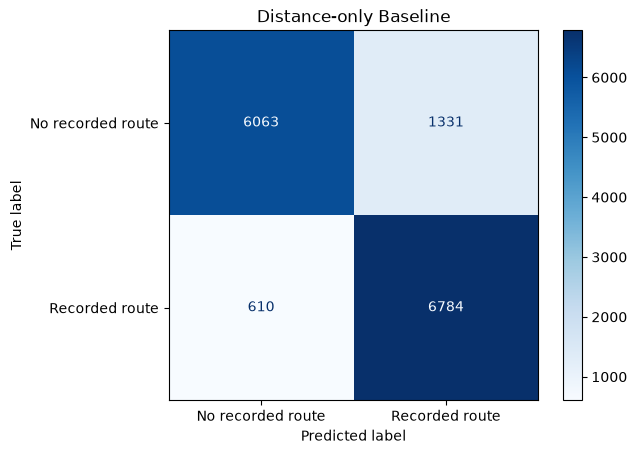

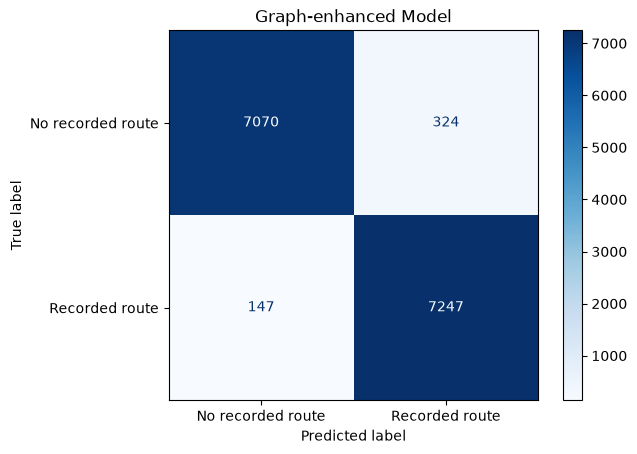

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

baseline_predictions = baseline_model.predict(X_test_baseline)
graph_predictions = graph_model.predict(X_test_graph)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_predictions,
    display_labels=["No recorded route", "Recorded route"],
    cmap="Blues",
)

plt.title("Distance-only Baseline")
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test,
    graph_predictions,
    display_labels=["No recorded route", "Recorded route"],
    cmap="Blues",
)

plt.title("Graph-enhanced Model")
plt.show()

## 19. Robustness Check — Distance-Matched Negative Sampling

The initial evaluation uses uniformly sampled negative airport pairs.

This may make classification relatively easy because randomly sampled
non-routes can differ considerably from recorded routes in geographic
distance.

To investigate this limitation, we construct an additional diagnostic
test set using non-routes with geographic distances similar to those
of held-out positive routes.

The objective is to determine whether graph-structural features remain
informative when geographic distance provides less separation between
the positive and negative classes.

The trained models remain unchanged.

This experiment is a robustness check rather than an independent
confirmation of real-world route-prediction performance.

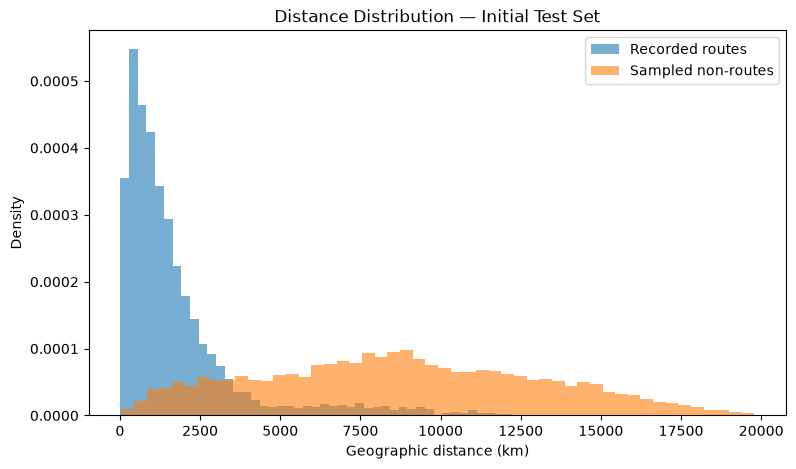

In [35]:
import matplotlib.pyplot as plt

positive_distances = test_ml_df.loc[
    test_ml_df["label"] == 1, "distance_km"
]

negative_distances = test_ml_df.loc[
    test_ml_df["label"] == 0, "distance_km"
]

plt.figure(figsize=(9, 5))

plt.hist(
    positive_distances,
    bins=50,
    alpha=0.6,
    label="Recorded routes",
    density=True,
)

plt.hist(
    negative_distances,
    bins=50,
    alpha=0.6,
    label="Sampled non-routes",
    density=True,
)

plt.xlabel("Geographic distance (km)")
plt.ylabel("Density")
plt.title("Distance Distribution — Initial Test Set")
plt.legend()
plt.show()

## 20. Robustness Evaluation — Distance-Matched Negatives

The initial distance distributions show that randomly sampled non-routes
are generally much farther apart than recorded routes.

This explains why geographic distance alone achieves strong
classification performance.

To investigate whether graph features remain informative under more
challenging conditions, we construct a second diagnostic test dataset.

For each positive test route, we attempt to select an unrecorded airport
pair with a similar geographic distance.

We preserve the original trained models and compare their performance
on this alternative test distribution.

This experiment tests robustness to negative-sampling choices.

It does not establish real-world performance or guarantee that sampled
non-routes are genuinely infeasible airline connections.

In [36]:
hard_rng = random.Random(RANDOM_STATE + 2)

candidate_negatives = sample_negative_routes(
    airport_ids=sampling_airports,
    existing_routes=existing_routes,
    n_samples=50000,
    rng=hard_rng,
    excluded_routes=train_negative_routes | test_negative_routes,
)

candidate_df = pd.DataFrame(
    sorted(candidate_negatives),
    columns=["source_id", "target_id"],
)

candidate_df["distance_km"] = [
    haversine_distance(source, target, airport_coordinates)
    for source, target in candidate_df[
        ["source_id", "target_id"]
    ].itertuples(index=False, name=None)
]

print("Candidate negatives:", len(candidate_df))

Candidate negatives: 50000


In [37]:
positive_test_df = test_ml_df[
    test_ml_df["label"] == 1
][["source_id", "target_id", "distance_km"]].copy()

positive_test_df = positive_test_df.sort_values("distance_km")

candidate_sorted = candidate_df.sort_values("distance_km")

matched_negatives = pd.merge_asof(
    positive_test_df[["distance_km"]],
    candidate_sorted,
    on="distance_km",
    direction="nearest",
)

matched_negatives = matched_negatives[
    ["source_id", "target_id", "distance_km"]
]

print("Matched negative examples:", len(matched_negatives))

Matched negative examples: 7394


In [38]:
distance_differences = abs(
    positive_test_df["distance_km"].to_numpy()
    - matched_negatives["distance_km"].to_numpy()
)

print(
    "Median distance difference:",
    round(np.median(distance_differences), 2),
    "km",
)

print(
    "95th percentile difference:",
    round(np.percentile(distance_differences, 95), 2),
    "km",
)

print(
    "Unique matched negatives:",
    len(
        matched_negatives[
            ["source_id", "target_id"]
        ].drop_duplicates()
    ),
)

Median distance difference: 0.0 km
95th percentile difference: 0.0 km
Unique matched negatives: 2374


In [39]:
# Calculate actual distances of the selected negative airport pairs.
matched_negatives["actual_distance_km"] = [
    haversine_distance(source, target, airport_coordinates)
    for source, target in matched_negatives[
        ["source_id", "target_id"]
    ].itertuples(index=False, name=None)
]

# Compare positive distances with actual negative distances.
distance_differences = np.abs(
    positive_test_df["distance_km"].to_numpy()
    - matched_negatives["actual_distance_km"].to_numpy()
)

print(
    "Corrected median distance difference:",
    round(np.median(distance_differences), 2),
    "km",
)

print(
    "Corrected 95th percentile difference:",
    round(np.percentile(distance_differences, 95), 2),
    "km",
)

Corrected median distance difference: 0.2 km
Corrected 95th percentile difference: 1.48 km


### Distance Matching Validation

The initial matching procedure reported zero geographic distance
differences because `merge_asof()` retained the positive-route
distance column used as its merge key.

Recalculating geographic distances from the matched negative airport
coordinates is necessary to obtain valid matching-error estimates.

Additionally, nearest-neighbor matching with replacement produced only
2,374 unique negative pairs from 7,394 matches.

We therefore need a matching procedure that produces unique negative
examples before evaluating model robustness.

### Unique Distance-Matched Negative Sampling

The initial nearest-neighbor matching procedure achieved small geographic
distance differences but reused negative airport pairs.

To avoid duplicate test examples, we implement greedy nearest-neighbor
matching without replacement.

Each negative candidate can be selected at most once.

The procedure preserves the test-set class balance while attempting
to minimize geographic distance differences.

We subsequently validate uniqueness, route absence, and matching quality.

In [40]:
import bisect

# Sort candidates by distance.
available_candidates = sorted(
    [
        (float(row.distance_km), int(row.source_id), int(row.target_id))
        for row in candidate_df.itertuples(index=False)
    ]
)

positive_test_sorted = positive_test_df.sort_values(
    "distance_km"
).reset_index(drop=True)

unique_matches = []

for positive_distance in positive_test_sorted["distance_km"]:
    # Find where this distance would appear among available candidates.
    position = bisect.bisect_left(
        available_candidates,
        (float(positive_distance), -1, -1),
    )

    # Check the closest candidate on either side.
    possible_positions = [
        index
        for index in (position - 1, position)
        if 0 <= index < len(available_candidates)
    ]

    closest_position = min(
        possible_positions,
        key=lambda index: abs(
            available_candidates[index][0] - positive_distance
        ),
    )

    distance, source_id, target_id = available_candidates.pop(
        closest_position
    )

    unique_matches.append(
        {
            "source_id": source_id,
            "target_id": target_id,
            "distance_km": distance,
        }
    )

unique_negative_df = pd.DataFrame(unique_matches)

print("Unique matched negatives:", len(unique_negative_df))

Unique matched negatives: 7394


In [41]:
unique_negative_pairs = set(
    unique_negative_df[["source_id", "target_id"]]
    .itertuples(index=False, name=None)
)

assert len(unique_negative_pairs) == len(test_routes)
assert not (unique_negative_pairs & existing_routes)
assert not (unique_negative_pairs & train_negative_routes)
assert not (unique_negative_pairs & test_negative_routes)

# Compare geographic distances in matched order.
matching_errors = np.abs(
    positive_test_sorted["distance_km"].to_numpy()
    - unique_negative_df["distance_km"].to_numpy()
)

print("Matched negatives:", len(unique_negative_pairs))
print("Median distance difference:", round(np.median(matching_errors), 2), "km")
print(
    "95th-percentile difference:",
    round(np.percentile(matching_errors, 95), 2),
    "km",
)

print("Unique matching validation passed.")

Matched negatives: 7394
Median distance difference: 863.83 km
95th-percentile difference: 1074.25 km
Unique matching validation passed.


In [42]:
train_unordered = {
    tuple(sorted(pair))
    for pair in train_negative_routes
}

hard_test_unordered = {
    tuple(sorted(pair))
    for pair in unique_negative_pairs
}

print(
    "Reciprocal overlap with training:",
    len(train_unordered & hard_test_unordered),
)

Reciprocal overlap with training: 27


### Revised Robustness Strategy — Distance-Restricted Negatives

The initial matching-with-replacement procedure produced highly similar
distances but repeated many negative examples.

Greedy matching without replacement eliminated duplicates but resulted
in poor matching quality because the candidate pool contained relatively
few short-distance non-routes.

We therefore use a simpler robustness strategy: sampling unique negative
airport pairs subject to a geographic distance restriction.

This makes the evaluation more challenging than uniform random negative
sampling while avoiding the complexity of exact distance matching.

The distance restriction is an experimental choice, not a claim about
the maximum distance of real airline routes.

In [43]:
positive_distances = test_ml_df.loc[
    test_ml_df["label"] == 1,
    "distance_km",
]

print("Median positive distance:", round(positive_distances.median(), 2))
print("75th percentile:", round(positive_distances.quantile(0.75), 2))
print("90th percentile:", round(positive_distances.quantile(0.90), 2))
print("95th percentile:", round(positive_distances.quantile(0.95), 2))

Median positive distance: 1138.81
75th percentile: 2068.9
90th percentile: 3654.8
95th percentile: 6501.8


### Distance-Restricted Robustness Evaluation

The recorded routes have a median geographic distance of 1,138.81 km
and a 90th-percentile distance of approximately 3,655 km.

We construct an additional diagnostic test dataset restricted to airport
pairs separated by no more than 3,655 km.

The restriction is applied to both positive and negative examples.

Negative examples are sampled from previously unrecorded directed routes,
excluding training examples and reciprocal training-negative pairs.

We preserve a balanced test set and evaluate the existing trained models
without retraining.

This experiment tests robustness within a geographically restricted
candidate population. It does not guarantee identical distance
distributions between positive and negative examples.

The threshold was chosen after inspecting the test data, so this
analysis is exploratory rather than an independent final evaluation.

In [44]:
DISTANCE_LIMIT_KM = 3655

restricted_positives = test_ml_df[
    (test_ml_df["label"] == 1)
    & (test_ml_df["distance_km"] <= DISTANCE_LIMIT_KM)
].copy()

print("Restricted positive examples:", len(restricted_positives))
print("Maximum distance:", restricted_positives["distance_km"].max())

Restricted positive examples: 6655
Maximum distance: 3654.79808205371


In [45]:
def unordered_pair(route):
    """Return an airport pair independently of direction."""
    return tuple(sorted(route))


train_negative_pairs = {
    unordered_pair(route)
    for route in train_negative_routes
}

eligible_negatives = candidate_df[
    candidate_df["distance_km"] <= DISTANCE_LIMIT_KM
].copy()

eligible_negatives = eligible_negatives[
    [
        unordered_pair((source, target)) not in train_negative_pairs
        for source, target in eligible_negatives[
            ["source_id", "target_id"]
        ].itertuples(index=False, name=None)
    ]
].copy()

print("Eligible negative candidates:", len(eligible_negatives))
print("Required negatives:", len(restricted_positives))

Eligible negative candidates: 7504
Required negatives: 6655


### Construction of the Distance-Restricted Test Set

We construct a balanced diagnostic dataset containing 6,655 recorded
routes and 6,655 sampled non-routes, all within 3,655 km.

Negative examples are selected without replacement from the eligible
candidate pool.

We retain the previously trained models to assess their performance
under a different negative-sampling strategy.

This experiment is exploratory because the distance threshold was
selected after examining the test data.

Restricting both classes to the same distance range does not guarantee
that their distance distributions are identical.

In [46]:
restricted_negatives = eligible_negatives.sample(
    n=len(restricted_positives),
    replace=False,
    random_state=RANDOM_STATE,
).copy()

print("Positive examples:", len(restricted_positives))
print("Negative examples:", len(restricted_negatives))

assert not restricted_negatives.duplicated(
    subset=["source_id", "target_id"]
).any()

print("Unique negative sampling validated.")

Positive examples: 6655
Negative examples: 6655
Unique negative sampling validated.


In [47]:
restricted_negative_pairs = list(
    restricted_negatives[["source_id", "target_id"]]
    .itertuples(index=False, name=None)
)

restricted_positive_pairs = list(
    restricted_positives[["source_id", "target_id"]]
    .itertuples(index=False, name=None)
)

restricted_test_df = build_feature_dataset(
    positive_routes=restricted_positive_pairs,
    negative_routes=restricted_negative_pairs,
    exclude_positive_candidates=False,
)

print("Restricted test dataset:", restricted_test_df.shape)

display(restricted_test_df.head())

Restricted test dataset: (13310, 7)


,source_id,target_id,distance_km,source_out_degree,target_in_degree,common_neighbors,label
0,1,2,106.713899,2,6,2,1
1,1,5,424.592807,2,21,1,1
2,2,1,106.713899,6,2,2,1
3,4,5,324.123553,7,21,6,1
4,4,5423,303.602001,7,1,0,1


In [48]:
restricted_pairs = set(restricted_negative_pairs)

assert len(restricted_pairs) == len(restricted_negatives)

assert not (restricted_pairs & existing_routes)

assert not (restricted_pairs & train_negative_routes)

assert (
    restricted_test_df["distance_km"] <= DISTANCE_LIMIT_KM
).all()

assert restricted_test_df["label"].value_counts().to_dict() == {
    1: 6655,
    0: 6655,
}

assert restricted_test_df[feature_columns].notna().all().all()

# Verify that no negative example shares an unordered
# airport pair with a training negative.
assert not (
    {unordered_pair(pair) for pair in restricted_pairs}
    & train_negative_pairs
)

print("Distance-restricted dataset validation passed.")

Distance-restricted dataset validation passed.


In [49]:
X_restricted_baseline = restricted_test_df[baseline_features]
X_restricted_graph = restricted_test_df[graph_features]

y_restricted = restricted_test_df["label"]

restricted_baseline_results = evaluate_model(
    baseline_model,
    X_restricted_baseline,
    y_restricted,
)

restricted_graph_results = evaluate_model(
    graph_model,
    X_restricted_graph,
    y_restricted,
)

restricted_comparison_df = pd.DataFrame(
    {
        "Distance baseline": restricted_baseline_results,
        "Graph-enhanced": restricted_graph_results,
    }
)

display(restricted_comparison_df.round(4))

,Distance baseline,Graph-enhanced
Precision,0.5000,0.7764
Recall,1.0000,0.9883
F1-score,0.6667,0.8696
ROC-AUC,0.7801,0.9531
Average precision,0.7724,0.9465


In [50]:
baseline_restricted_predictions = baseline_model.predict(
    X_restricted_baseline
)

print(
    "Predicted recorded routes:",
    (baseline_restricted_predictions == 1).sum(),
)

print(
    "Predicted non-routes:",
    (baseline_restricted_predictions == 0).sum(),
)

Predicted recorded routes: 13310
Predicted non-routes: 0


In [51]:
restricted_isolated_mask = (
    restricted_positives["source_id"].isin(isolated_airports)
    | restricted_positives["target_id"].isin(isolated_airports)
)

affected_restricted_positives = restricted_isolated_mask.sum()

print(
    "Restricted positives involving isolated airports:",
    affected_restricted_positives,
)

print(
    "Percentage:",
    round(
        affected_restricted_positives
        / len(restricted_positives) * 100,
        2,
    ),
    "%",
)

Restricted positives involving isolated airports: 400
Percentage: 6.01 %


## 22. Results and Discussion

### Experimental Objective

This experiment investigated whether graph-structural features improve
the identification of held-out historical airline connections compared
with geographic distance alone.

Two Logistic Regression models were trained:

- **Distance baseline:** Geographic distance only.
- **Graph-enhanced model:** Geographic distance, source out-degree,
  destination in-degree, and common neighbors.

Both models were evaluated on held-out directed connections from
the historical OpenFlights network.

### Initial Evaluation

The initial test dataset contained 7,394 recorded routes and
7,394 uniformly sampled unrecorded airport pairs.

| Metric | Distance Baseline | Graph-Enhanced |
|---|---:|---:|
| Precision | 0.8360 | **0.9572** |
| Recall | 0.9175 | **0.9801** |
| F1-score | 0.8748 | **0.9685** |
| ROC-AUC | 0.9357 | **0.9922** |
| Average precision | 0.9309 | **0.9907** |

The graph-enhanced model outperformed the geographic baseline
across all reported metrics.

However, analysis of geographic distance distributions revealed that
uniformly sampled non-routes were generally much farther apart than
recorded routes, making the initial classification task relatively easy.

### Distance-Restricted Robustness Evaluation

To examine this limitation, a second diagnostic test dataset was
constructed using airport pairs separated by no more than 3,655 km.

This dataset contained 6,655 recorded routes and 6,655 sampled
unrecorded routes.

The original trained models were evaluated without retraining.

| Metric | Distance Baseline | Graph-Enhanced |
|---|---:|---:|
| Precision | 0.5000 | **0.7764** |
| Recall | **1.0000** | 0.9883 |
| F1-score | 0.6667 | **0.8696** |
| ROC-AUC | 0.7801 | **0.9531** |
| Average precision | 0.7724 | **0.9465** |

Both models performed worse under the more challenging geographic
restriction.

The geographic baseline predicted every example as a recorded route
at its default classification threshold.

Despite this, its ROC-AUC remained above 0.5, indicating that its
continuous scores retained some ranking ability.

The graph-enhanced model maintained substantially stronger
discrimination, achieving an ROC-AUC of 0.9531.

### Interpretation

These findings suggest that graph-structural information contributes
useful predictive information beyond geographic distance.

In particular, airport degree and shared neighborhood structure
appear to help distinguish recorded connections from sampled
non-routes.

However, these results describe performance under the selected
experimental sampling procedures.

They do not establish the ability to forecast future airline routes.

### Methodological Limitations

1. **Historical data:** OpenFlights contains historical route records,
   not current or future airline schedules.

2. **Negative sampling:** Unrecorded routes are treated as negative
   examples, although their absence does not imply impossibility.

3. **Artificial class balance:** Both evaluation datasets contain
   equal numbers of positive and negative examples. They do not
   represent natural route prevalence.

4. **Geographic sampling bias:** Uniform negative sampling produces
   geographically distant airport pairs, making classification easier.

5. **Diagnostic threshold selection:** The 3,655 km restriction was
   selected after inspecting the held-out distance distribution,
   making the robustness evaluation exploratory.

6. **Training graph structure:** Holding out connections isolated
   177 airports. In the restricted test set, 400 positive examples
   (6.01%) involved at least one newly isolated airport, while
   negative examples were sampled from training-active airports.

7. **Feature construction:** Training-positive features were
   calculated by excluding each candidate edge individually.
   This differs from the feature-generation conditions of the test
   partition and may influence evaluation.

8. **Operational factors:** The model does not incorporate passenger
   demand, airline capacity, schedules, or economic constraints.

### Conclusion

The graph-enhanced Logistic Regression model outperformed the
geographic-distance baseline under both uniform and distance-restricted
negative sampling.

The findings support the usefulness of graph-structural features
for identifying held-out historical airline connections.

Nevertheless, results depend on the construction of negative examples
and the assumptions of the evaluation methodology.

The experiment demonstrates a reproducible supervised link-prediction
workflow integrated with the FlightGraph graph database.